# 02 · LoRA fine-tuning: Qwen3-4B-Instruct-2507 on CUAD clause extraction

**Goal:** adapt `Qwen/Qwen3-4B-Instruct-2507` with LoRA to the category-conditioned clause-extraction task built in
`src/build_dataset.py` (see `data/processed/cuad_v1/DATA_CARD.md`), with every hyperparameter derived or justified.

**How this notebook is organised:** the notebook holds the *decisions*. Training itself runs in
`src/train_lora.py` (a thin MLX-LM wrapper), so the run is reproducible from the command line and survives a kernel
restart. The notebook writes the config, runs a smoke test, launches the full run, and monitors it.

| Step | What it does |
|---|---|
| 1 | Environment and inputs (versions, hardware, dataset hash, test-set guard) |
| 2 | Base model facts (architecture, size, license) |
| 3 | Chat template and loss mask: exactly which tokens are trained |
| 4 | Real token lengths → `max_seq_length` (no silent truncation) |
| 5 | Hyperparameters, each with its rationale and rejected alternatives → `configs/*.yaml` |
| 6 | Trainable parameters and memory budget |
| 7 | Smoke test (20 iterations): pipeline check plus measured throughput → time estimate |
| 8 | Full training run (background process) |
| 9 | Monitoring: loss curves and best checkpoint |
| 10 | Sanity generation with the trained adapter on validation chunks |

**Kernel:** `Python (track-b-slm)`. **The test set is never touched here.** Model selection uses validation only.

In [1]:
import json, math, os, platform, subprocess, sys, time
from pathlib import Path

import matplotlib.pyplot as plt
import mlx.core as mx
import numpy as np
import pandas as pd
import yaml
import mlx_lm
from transformers import AutoTokenizer

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "CLAUDE.md").exists() and (p / "src").exists())
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)
DATA = ROOT / "data/processed/cuad_v1"
MODEL_ID = "Qwen/Qwen3-4B-Instruct-2507"
SEED = 42

BLUE, ORANGE, INK2 = "#2a78d6", "#eb6834", "#52514e"
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#d9d8d3",
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#ecebe7",
                     "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.labelcolor": INK2,
                     "xtick.color": INK2, "ytick.color": INK2, "figure.dpi": 110})

dev = mx.device_info()
env = {"python": platform.python_version(), "mlx": mx.__version__, "mlx_lm": mlx_lm.__version__,
       "device": dev["device_name"], "unified_memory_GB": round(dev["memory_size"] / 2**30, 1),
       "max_recommended_working_set_GB": round(dev["max_recommended_working_set_size"] / 2**30, 1),
       "git_commit": subprocess.run(["git", "rev-parse", "--short", "HEAD"], capture_output=True, text=True).stdout.strip()}
pd.Series(env).to_frame("value")

/Users/alok/Documents/01_projects/11_self/08_challenge_ava/02_slm_finetuning/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,value
python,3.12.13
mlx,0.32.4
mlx_lm,0.32.2
device,Apple M5 Pro
unified_memory_GB,48.0
max_recommended_working_set_GB,37.4
git_commit,4578b7d


## Step 1 · Inputs
The training data comes from `python -m src.build_dataset` (deterministic, seed 42). We print its hash so every run can
be traced to the exact data it saw. Only `train.jsonl` and `valid.jsonl` are used here.

In [2]:
stats = json.loads((DATA / "stats.json").read_text())
print("train.jsonl sha256[:16]:", stats["train_sha256_16"])
print("contracts per split   :", stats["contracts"])
print("train / valid examples:", stats["files"]["train.jsonl"], "/", stats["files"]["valid.jsonl"])
print("train all-empty share :", f'{stats["train_examples"]["all_empty"] / stats["train_examples"]["n"]:.0%}')
# Guard: no test contract may appear in the training or validation files
split = json.loads((DATA / "splits.json").read_text())
seen = {json.loads(l)["contract"] for f in ("train_meta.jsonl", "valid_meta.jsonl") for l in open(DATA / f)}
leak = [c for c in seen if split[c] == "test"]
assert not leak, f"test contracts found in train/valid: {leak[:3]}"
print("test-set guard        : OK (0 test contracts in train/valid)")

train.jsonl sha256[:16]: 2cedaea7f8f74e2d
contracts per split   : {'test': 80, 'val': 80, 'train': 350}
train / valid examples: 2997 / 649
train all-empty share : 34%
test-set guard        : OK (0 test contracts in train/valid)


## Step 2 · Base model: `Qwen/Qwen3-4B-Instruct-2507`
**Why this model** (the full comparison is in the conversation notes and will go in the write-up):
- **4B dense transformer** (standard `qwen3` architecture) with mature MLX-LM LoRA support. On a 48 GB M5 Pro it trains in
  full bf16 (no quantization), fast enough to afford ablations within 48 h.
- **Instruct-2507 is the non-thinking variant**: it answers with JSON directly, with no `<think>` block to strip or pay for.
- **Apache-2.0**, ungated, with 256k native context (we need about 4k).

**Rejected:**
- **Qwen3.5-4B/9B:** hybrid linear-attention plus vision wrapper; open MLX-LM issues for exactly this (a memory crash in
  LoRA training, slow linear-attention backward).
- **Qwen3-8B:** 2× the cost; kept as the step up if 4B plateaus.
- **Llama-3.2-3B / 3.1-8B:** older and weaker at long-context instruction following; more restrictive license.
- **Gemma-3/4:** gated, with restrictive terms.
- **Phi-4-mini:** no advantage for long-context extraction.

In [3]:
from huggingface_hub import snapshot_download
model_dir = Path(snapshot_download(MODEL_ID, allow_patterns=["*.json", "*.safetensors", "*.txt", "merges.txt", "vocab.json", "LICENSE"]))
cfg = json.loads((model_dir / "config.json").read_text())
idx = json.loads((model_dir / "model.safetensors.index.json").read_text())
arch = {k: cfg.get(k) for k in ["architectures", "model_type", "num_hidden_layers", "hidden_size", "intermediate_size",
                                 "num_attention_heads", "num_key_value_heads", "head_dim", "vocab_size",
                                 "max_position_embeddings", "torch_dtype", "tie_word_embeddings"]}
arch["weights_size_GB (bf16)"] = round(idx["metadata"]["total_size"] / 1e9, 2)
arch["approx_params_B"] = round(idx["metadata"]["total_size"] / 2 / 1e9, 2)
pd.Series(arch).to_frame("value")

Fetching 11 files: 100%|██████████| 11/11 [00:00<00:00, 2360.45it/s]


,value
architectures,[Qwen3ForCausalLM]
model_type,qwen3
num_hidden_layers,36
hidden_size,2560
intermediate_size,9728
num_attention_heads,32
num_key_value_heads,8
head_dim,128
vocab_size,151936
max_position_embeddings,262144


In [4]:
model_dir

PosixPath('/Users/alok/.cache/huggingface/hub/models--Qwen--Qwen3-4B-Instruct-2507/snapshots/cdbee75f17c01a7cc42f958dc650907174af0554')

## Step 3 · Chat template and loss mask
MLX-LM renders each `{"messages": [...]}` example with the model's own chat template. With `mask_prompt: true`, **loss
is computed only on the assistant answer**. The offset is the token length of the rendered
`system + user + "<|im_start|>assistant\n"` prefix. Below we render one real training example and show the boundary.

In [5]:
tok = AutoTokenizer.from_pretrained(model_dir)
train_rows = [json.loads(l) for l in open(DATA / "train.jsonl")]
valid_rows = [json.loads(l) for l in open(DATA / "valid.jsonl")]

def render(msgs):
    full = tok.apply_chat_template(msgs, tokenize=True, return_dict=False)
    prefix = tok.apply_chat_template(msgs[:-1], tokenize=True, add_generation_prompt=True, return_dict=False)  # = mlx-lm's offset
    return full, len(prefix)

ex = next(r for r in train_rows if json.loads(r["messages"][2]["content"]) and any(json.loads(r["messages"][2]["content"]).values()))
full, off = render(ex["messages"])
text = tok.decode(full)
print(f"total tokens {len(full)} | masked (prompt) {off} | trained (answer) {len(full) - off}\n")
print("── start of rendered sequence ──\n" + tok.decode(full[:60]) + " …\n")
print("── around the loss boundary (│ marks where loss starts) ──")
print(tok.decode(full[off - 25:off]) + "│" + tok.decode(full[off:off + 60]) + " …")
print("\n── end of sequence ──\n…" + tok.decode(full[-15:]))
assert "<think>" not in text, "unexpected thinking block in template"

total tokens 1854 | masked (prompt) 1705 | trained (answer) 149

── start of rendered sequence ──
<|im_start|>system
You are a contract-review assistant for a procurement team. You extract clauses from contract excerpts. Quotes must be copied verbatim from the excerpt. A category that is not present gets an empty list. Output JSON only.<|im_end|>
<|im_start|>user
Extract the following clause categories from the contract excerpt …

── around the loss boundary (│ marks where loss starts) ──
 faith and reasonable development efforts, only that party may exercise the foregoing right to terminate.


</excerpt><|im_end|>
<|im_start|>assistant
│{"Agreement Date": ["June 21, 1999"], "Expiration Date": [], "Governing Law": [], "Uncapped Liability": [], "Notice Period To Terminate Renewal": [], "Anti-Assignment": [], "Renewal Term": [], "Ex …

── end of sequence ──
…VERTISING AGREEMENT"], "Termination For Convenience": []}<|im_end|>



**Check:** the trained region starts right after `<|im_start|>assistant\n` and ends with `<|im_end|>`, so the model
learns to *stop* after the JSON. There is no `<think>` block, as expected for the Instruct-2507 variant.

## Step 4 · Real token lengths → `max_seq_length`
The data card used a chars / 4 estimate. Now we measure with the real tokenizer. **MLX-LM silently truncates sequences
longer than `max_seq_length`**, which here would cut off the end of the excerpt or the answer itself. So we set it
from the measured maximum, and `src/train_lora.py` refuses to train if anything still exceeds it.

count    mean    std    min     50%     90%     99%     max
train total   2997.0  1736.0  303.0  504.0  1726.0  2052.0  2514.0  5389.0
      prompt  2997.0  1579.0  258.0  466.0  1584.0  1806.0  2198.0  5330.0
      answer  2997.0   158.0  130.0   24.0   117.0   307.0   655.0  1307.0
valid total    649.0  1717.0  298.0  523.0  1722.0  2031.0  2452.0  3522.0
      prompt   649.0  1562.0  255.0  482.0  1579.0  1780.0  2189.0  3462.0
      answer   649.0   154.0  119.0   25.0   118.0   315.0   547.0   832.0

chars/token (measured): 4.76  (data-card estimate was 4.0)
share of tokens that are the answer (trained with mask_prompt): 9.1%
longest example: 5389 tokens → max_seq_length = 5632 (0 examples truncated)


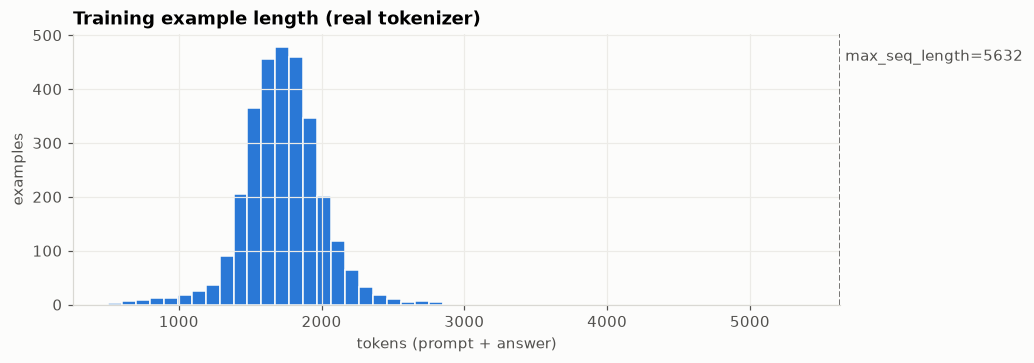

In [6]:
def lengths(rows):
    out = []
    for r in rows:
        full, off = render(r["messages"])
        out.append({"total": len(full), "prompt": off, "answer": len(full) - off,
                    "chars": sum(len(m["content"]) for m in r["messages"])})
    return pd.DataFrame(out)

L_train, L_valid = lengths(train_rows), lengths(valid_rows)
L_train["chars_per_token"] = L_train.chars / L_train.total
display(pd.concat({"train": L_train[["total", "prompt", "answer"]].describe(percentiles=[.5, .9, .99]).T,
                   "valid": L_valid[["total", "prompt", "answer"]].describe(percentiles=[.5, .9, .99]).T}).round(0))
print(f"chars/token (measured): {L_train.chars_per_token.median():.2f}  (data-card estimate was 4.0)")
answer_share = L_train.answer.sum() / L_train.total.sum()
print(f"share of tokens that are the answer (trained with mask_prompt): {answer_share:.1%}")

longest = int(max(L_train.total.max(), L_valid.total.max()))
MAX_SEQ = int(math.ceil((longest + 1) / 256) * 256)  # +1 for padding alignment; round up to a multiple of 256
print(f"longest example: {longest} tokens → max_seq_length = {MAX_SEQ} (0 examples truncated)")

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.hist(L_train.total, bins=50, color=BLUE, edgecolor="#fcfcfb")
ax.axvline(MAX_SEQ, color=INK2, ls="--", lw=1); ax.text(MAX_SEQ, ax.get_ylim()[1] * .9, f" max_seq_length={MAX_SEQ}", color=INK2)
ax.set_title("Training example length (real tokenizer)"); ax.set_xlabel("tokens (prompt + answer)"); ax.set_ylabel("examples")
plt.show()

**Why `mask_prompt` matters here:** the answer is only a small share of each sequence (printed above). Without masking,
almost all of the gradient would go into predicting *contract text*, which is language modelling on SEC exhibits, not
the extraction skill. The answer tokens would be a rounding error in the loss.

## Step 5 · Hyperparameters
Every value below is either **derived** (from data or hardware) or **chosen** with a reason and a rejected alternative.

| Parameter | Value | Why | Alternatives considered |
|---|---|---|---|
| Method | **LoRA** on a **bf16** base | 4B bf16 weights (~8 GB) fit easily in 48 GB, so there is no need to quantize the base. Quantization (QLoRA) would add noise to both the baseline and the fine-tuned model. | **QLoRA** (4-bit base): saves memory we don't need, and the 4-bit rounding blurs the base-vs-FT comparison. **DoRA**: slower per step (an extra weight-norm computation), with gains mostly reported at low rank. Kept as an ablation. **Full fine-tuning**: 4B × (weights + Adam states) ≈ 64 GB, which doesn't fit, and is easier to overfit with 3k examples. |
| Target modules | **all 7 linear layers** per block: `q,k,v,o` + `gate,up,down` | The task needs new *decision boundaries* (which clause is which), not just a new style. The QLoRA paper (Dettmers et al. 2023) found that adapting all linear layers is what closes the gap to full fine-tuning; attention-only LoRA underfits. | **Attention only** (`q,v`, the original LoRA paper): fewer parameters but weaker on knowledge-heavy tasks. |
| Layers | **all 36** (`num_layers: -1`) | The task changes both *what* is selected (clause semantics) and *how* it is written (schema). We don't know a priori which depth matters, and adapting all layers costs little extra (see Step 6). | **Top 16** (the mlx-lm default): cheaper. A reasonable ablation, but not the default without evidence. |
| Rank `r` | **16** | Enough capacity for 16 category boundaries plus the output schema; ~0.8% of weights become trainable. | **8**: may underfit the boundaries. **32/64**: more capacity than 3k examples justify, and a higher memorization risk. Rank 8 vs 32 is a planned ablation. |
| Scale (= α / r) | **2.0** (i.e. α = 32) | The common α = 2r convention. mlx-lm takes `scale` directly; its default of 20 pairs with its default LR of 1e-5. We use the conventional α/r with a conventional LoRA LR, so values are comparable with the PEFT literature. | **scale 20 + LR 1e-5** (mlx-lm default): equivalent in effective step size, but non-standard and harder to compare with the literature. |
| LoRA dropout | **0.05** | Light regularisation; 3k examples over 2 epochs can memorise. | **0.0**: faster fit, more overfitting. **0.1**: often used for under 1k examples. |
| Optimizer | **AdamW**, weight decay 0.01 | Standard for LoRA; decoupled decay gives mild regularisation. | **Adam** (the mlx-lm default): no decay. **Adafactor/Muon**: memory savings we don't need, and less evidence for LoRA. |
| Peak LR | **1e-4** | Typical LoRA range is 1e-4 to 2e-4 at α/r = 2. We take the conservative end because the base model is already instruction-tuned and we don't want to damage its general ability (forgetting is measured later). | **2e-4**: faster convergence in 375 updates, but riskier for forgetting; the natural ablation if validation loss is still falling. **1e-5**: far too slow for 375 updates. |
| Schedule | **linear warmup (5% of updates) → cosine decay to 10% of peak** | Warmup avoids early large updates on randomly initialised A·B (B starts at 0). Cosine gives a gentle end. | **Constant LR**: noisier end of training, and the best checkpoint is more sensitive to when we stop. |
| Micro-batch × grad accumulation | **2 × 4 = 8 effective** | Memory: logits are batch × seq × 152k vocab, the largest activation, so a micro-batch of 2 keeps peak memory safe (measured in Step 7). An effective batch of 8 gives a stable gradient on mixed positive/negative examples. | **Micro-batch 4–8**: higher logits memory for little speed gain on Apple GPUs. **Effective batch 16–32**: fewer updates (~200–400) for 3k examples. |
| Epochs → iterations | **1 epoch** → derived `iters` (375 updates) | **Compute-bound decision (measured in Step 7):** about 13.5 s per iteration on the M5 Pro, so 1 epoch ≈ 5.6 h and 2 epochs ≈ 11 h. That is too much of a 48 h window that also needs evaluation and ablations. Each example is seen once, which also lowers memorization risk. The **best checkpoint by validation loss** is kept. | **2 epochs** (≈ 13 h with validation): would help the rarest categories (~100 positives); the first option to revisit if validation loss is still falling at the end. **3+ epochs**: memorization risk. |
| `max_seq_length` | **derived in Step 4** | No example is truncated. | **2048** (default): would truncate most examples. |
| `mask_prompt` | **true** | Train on answer tokens only (Step 4). | **false**: the loss is dominated by contract text. |
| Gradient checkpointing | **on** | **Measured:** with it off, micro-batch 2 ran out of GPU memory (Metal `kIOGPUCommandBufferCallbackErrorOutOfMemory`). With it on, peak memory is 16.5 GB. It recomputes activations in the backward pass (roughly a third more compute). | **off**: OOM at micro-batch 2. **off + micro-batch 1**: might fit typical 1.7k-token examples, but the 5.4k-token outlier risks OOM mid-run. |
| Validation | fixed **96-example** subset of `valid.jsonl`, evaluated in full every **250 iterations** (~62 updates) | Comparable loss across evaluations (mlx-lm otherwise re-samples batches). Measured forward speed ≈ 830 tokens/s, so ≈ 3.4 min per evaluation and 8 evaluations ≈ 0.4 h. | Full 649-example validation: ≈ 23 min per evaluation. Random `val_batches`: noisy curve. |
| Seed | **42** | Matches the dataset split. | None. |

In [7]:
N_TRAIN = len(train_rows)
BATCH, ACCUM, EPOCHS = 2, 4, 1
iters = math.ceil(EPOCHS * N_TRAIN / BATCH / ACCUM) * ACCUM     # micro-batches, a multiple of ACCUM
updates = iters // ACCUM                                        # optimizer steps (what the LR schedule counts)
warmup = max(1, round(0.05 * updates))
PEAK_LR = 1e-4

CONFIG = {
    "run_name": "qwen3-4b-lora-r16-v1",
    "model": MODEL_ID,
    "dataset_dir": "data/processed/cuad_v1",
    "valid_subset": 96,
    "seed": SEED,
    "fine_tune_type": "lora",
    "num_layers": -1,
    "lora_parameters": {"rank": 16, "scale": 2.0, "dropout": 0.05,
                        "keys": ["self_attn.q_proj", "self_attn.k_proj", "self_attn.v_proj", "self_attn.o_proj",
                                 "mlp.gate_proj", "mlp.up_proj", "mlp.down_proj"]},
    "optimizer": "adamw",
    "optimizer_config": {"adamw": {"weight_decay": 0.01}},
    "learning_rate": PEAK_LR,
    "lr_schedule": {"name": "cosine_decay", "warmup": warmup, "warmup_init": PEAK_LR / 100,
                    "arguments": [PEAK_LR, updates - warmup, PEAK_LR / 10]},
    "batch_size": BATCH,
    "grad_accumulation_steps": ACCUM,
    "iters": iters,
    "max_seq_length": MAX_SEQ,
    "mask_prompt": True,
    "grad_checkpoint": True,
    "steps_per_report": 20,
    "steps_per_eval": 250,
    "save_every": 250,
    "val_batches": -1,
}
CONFIG_PATH = ROOT / "configs" / "qwen3-4b-lora-r16.yaml"
CONFIG_PATH.parent.mkdir(exist_ok=True)
CONFIG_PATH.write_text("# Generated by notebooks/02_train_lora_qwen3_4b.ipynb (Step 5). Rationale for every value is in that notebook.\n"
                       + yaml.safe_dump(CONFIG, sort_keys=False))
print(f"{N_TRAIN} examples × {EPOCHS} epochs / micro-batch {BATCH} → iters={iters} micro-batches = {updates} optimizer updates "
      f"(warmup {warmup}, cosine over {updates - warmup})")
print(f"validation every {CONFIG['steps_per_eval']} iters → {iters // CONFIG['steps_per_eval'] + 2} evaluations (incl. untrained baseline and final)")
print(f"wrote {CONFIG_PATH.relative_to(ROOT)}")

2997 examples × 1 epochs / micro-batch 2 → iters=1500 micro-batches = 375 optimizer updates (warmup 19, cosine over 356)
validation every 250 iters → 8 evaluations (incl. untrained baseline and final)
wrote configs/qwen3-4b-lora-r16.yaml


## Step 6 · Trainable parameters and memory budget
LoRA adds `r × (d_in + d_out)` parameters per adapted matrix. The memory estimate is deliberately rough. Step 7
measures the real peak.

In [8]:
h, inter, L = cfg["hidden_size"], cfg["intermediate_size"], cfg["num_hidden_layers"]
hd = cfg.get("head_dim") or h // cfg["num_attention_heads"]
q_out, kv_out = cfg["num_attention_heads"] * hd, cfg["num_key_value_heads"] * hd
shapes = {"q_proj": (h, q_out), "k_proj": (h, kv_out), "v_proj": (h, kv_out), "o_proj": (q_out, h),
          "gate_proj": (h, inter), "up_proj": (h, inter), "down_proj": (inter, h)}
r = CONFIG["lora_parameters"]["rank"]
per_layer = {k: r * (a + b) for k, (a, b) in shapes.items()}
lora_params = sum(per_layer.values()) * L
base_params = arch["approx_params_B"] * 1e9
display(pd.DataFrame({"d_in × d_out": {k: f"{a} × {b}" for k, (a, b) in shapes.items()},
                      "LoRA params / layer": per_layer}))
print(f"LoRA trainable parameters: {lora_params/1e6:.1f} M = {lora_params/base_params:.2%} of {base_params/1e9:.2f} B")

GB = 1e9
mem = {
    "base weights (bf16)": base_params * 2 / GB,
    "LoRA weights + grads + AdamW m,v (fp32)": lora_params * 4 * 4 / GB,
    "logits + grad (fp32), micro-batch × max_seq × vocab": BATCH * MAX_SEQ * cfg["vocab_size"] * 4 * 2 / GB,
    "checkpointed hidden states (bf16)": BATCH * MAX_SEQ * h * 2 * L / GB,
}
mem["≈ total (before allocator overhead)"] = sum(mem.values())
display(pd.Series(mem).round(1).to_frame("GB (rough)"))
print(f"Budget: {env['max_recommended_working_set_GB']} GB recommended GPU working set → the micro-batch of {BATCH} leaves headroom.")

,d_in × d_out,LoRA params / layer
q_proj,2560 × 4096,106496
k_proj,2560 × 1024,57344
v_proj,2560 × 1024,57344
o_proj,4096 × 2560,106496
gate_proj,2560 × 9728,196608
up_proj,2560 × 9728,196608
down_proj,9728 × 2560,196608


LoRA trainable parameters: 33.0 M = 0.82% of 4.02 B


,GB (rough)
base weights (bf16),8.0
"LoRA weights + grads + AdamW m,v (fp32)",0.5
"logits + grad (fp32), micro-batch × max_seq × vocab",13.7
checkpointed hidden states (bf16),2.1
≈ total (before allocator overhead),24.3


Budget: 37.4 GB recommended GPU working set → the micro-batch of 2 leaves headroom.


## Step 7 · Smoke test (20 iterations)
Before committing hours of compute: run the **real pipeline** (same config, same script) for 20 iterations on a small
validation subset. It checks that the model loads, no example is truncated, loss is finite and decreasing-ish, and
adapters are saved. It also measures **tokens/s and peak memory**, from which we estimate the full run time.

In [9]:
smoke_name = "smoke-" + time.strftime("%Y%m%d-%H%M%S")
cmd = [sys.executable, "-m", "src.train_lora", "--config", str(CONFIG_PATH), "--override",
       f"run_name={smoke_name}", "iters=20", "steps_per_eval=10", "steps_per_report=5", "save_every=10", "valid_subset=16"]
print(" ".join(cmd[1:]), "\n")
t0 = time.time()
proc = subprocess.run(cmd, cwd=ROOT, capture_output=True, text=True)
smoke_wall = time.time() - t0
keep = [l for l in proc.stdout.splitlines() if l.startswith(("[train]", "[val]", "[best]", "lengths", "done", "Loading"))]
print("\n".join(keep))
if proc.returncode != 0:
    print(proc.stdout[-3000:], proc.stderr[-3000:])
    raise RuntimeError("smoke test failed")
print(f"\nwall time {smoke_wall:.0f}s (includes model load)")

-m src.train_lora --config /Users/alok/Documents/01_projects/11_self/08_challenge_ava/02_slm_finetuning/configs/qwen3-4b-lora-r16.yaml --override run_name=smoke-20261114-215107 iters=20 steps_per_eval=10 steps_per_report=5 save_every=10 valid_subset=16 

Loading Qwen/Qwen3-4B-Instruct-2507 ...
lengths OK: {'train': {'n': 2997, 'max': 5389, 'mean': 1736.3, 'total_tokens': 5203750}, 'valid': {'n': 16, 'max': 2028, 'mean': 1762.1, 'total_tokens': 28194}}

wall time 1029s (includes model load)


In [ ]:
smoke_dir = ROOT / "runs" / smoke_name
m = pd.DataFrame([json.loads(l) for l in open(smoke_dir / "metrics.jsonl")])
tr, va = m[m.kind == "train"].reset_index(drop=True), m[m.kind == "val"].reset_index(drop=True)
assert np.isfinite(tr.train_loss).all() and (smoke_dir / "best" / "adapters.safetensors").exists()
peak = tr.peak_memory.max()
# NB: mlx-lm's tokens_per_second counts *trained* (answer) tokens only, because of mask_prompt. For cost we need wall
# time per iteration: the gap between train reports, minus any validation that ran in between, skipping the first
# report (it includes compilation warm-up).
gaps = []
for i in range(1, len(tr)):
    lo, hi = tr.wall_s[i - 1], tr.wall_s[i]
    val_between = va[(va.wall_s > lo) & (va.wall_s <= hi)].val_time.sum()
    gaps.append((hi - lo - val_between) / (tr.iteration[i] - tr.iteration[i - 1]))
sec_per_iter = float(np.mean(gaps))
proc_tok_s = BATCH * L_train.total.mean() / sec_per_iter                 # all processed tokens (prompt + answer)
val_tok_s = (va.val_time.mean() and (16 * L_valid.total.mean()) / va.val_time.mean())   # smoke used valid_subset=16
n_evals = math.ceil(iters / CONFIG["steps_per_eval"]) + 1
train_h = iters * sec_per_iter / 3600
val_h = n_evals * CONFIG["valid_subset"] * L_valid.total.mean() / val_tok_s / 3600
pd.Series({"seconds / iteration (measured)": round(sec_per_iter, 1),
           "processed tokens/s, train (fwd+bwd)": round(proc_tok_s), "tokens/s, validation (fwd)": round(val_tok_s),
           "peak memory GB (measured)": round(peak, 1), "iterations": iters, "evaluations": n_evals,
           "est. training hours": round(train_h, 1), "est. validation hours": round(val_h, 2),
           "est. total hours": round(train_h + val_h, 1)}).to_frame("smoke test → full-run estimate")

## Step 8 · Full training run
This runs for hours, so it is launched as a **background process** with its own log. Closing or restarting the notebook does
not stop it. Set `RUN_FULL = True` to launch. Equivalent CLI:
```
.venv/bin/python -m src.train_lora --config configs/qwen3-4b-lora-r16.yaml
```
Outputs go to `runs/<run_name>/`: `config.yaml`, `run_info.json`, `metrics.jsonl`, `train.log`, `adapters/` (mlx-lm
checkpoints every 250 iterations) and **`best/`** (the exact weights with the lowest validation loss, loadable as an adapter).

In [ ]:
RUN_FULL = False   # ← set True to launch (takes the estimated hours above)
RUN_NAME = CONFIG["run_name"]
run_dir = ROOT / "runs" / RUN_NAME
if RUN_FULL:
    assert not (run_dir / "metrics.jsonl").exists(), f"{RUN_NAME} already exists; choose a new run_name"
    run_dir.mkdir(parents=True, exist_ok=True)
    log = open(run_dir / "train.log", "w")
    p = subprocess.Popen([sys.executable, "-m", "src.train_lora", "--config", str(CONFIG_PATH)],
                         cwd=ROOT, stdout=log, stderr=subprocess.STDOUT, start_new_session=True)
    (run_dir / "PID").write_text(str(p.pid))
    print(f"launched PID {p.pid}; follow with:  tail -f {run_dir.relative_to(ROOT)}/train.log")
else:
    print("RUN_FULL is False: not launching. Monitoring below shows the most recent run that exists.")

## Step 9 · Monitor
Re-run this cell at any time. Train and validation loss share one axis (same unit: mean token cross-entropy on answer
tokens). The learning rate and throughput are separate charts.

**What to look for:**
- validation loss falling, then flattening: the best checkpoint is where it bottoms out;
- validation loss rising while train loss keeps falling: overfitting, and `best/` already holds the earlier weights;
- throughput dips: memory pressure (other apps).

In [ ]:
def latest_run():
    full = ROOT / "runs" / CONFIG["run_name"]
    if (full / "metrics.jsonl").exists():
        return full
    runs = sorted((p for p in (ROOT / "runs").glob("*") if (p / "metrics.jsonl").exists()), key=lambda p: p.stat().st_mtime)
    return runs[-1] if runs else None

rd = latest_run()
print("run:", rd.relative_to(ROOT))
M = pd.DataFrame([json.loads(l) for l in open(rd / "metrics.jsonl")])
T, V = M[M.kind == "train"], M[M.kind == "val"]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
ax = axes[0]
ax.plot(T.iteration, T.train_loss, color=BLUE, lw=2, label="train loss")
ax.plot(V.iteration, V.val_loss, color=ORANGE, lw=2, marker="o", ms=5, label="validation loss")
if (rd / "best" / "best.json").exists():
    b = json.loads((rd / "best" / "best.json").read_text())
    ax.axvline(b["iteration"], color=INK2, ls="--", lw=1); ax.text(b["iteration"], ax.get_ylim()[1], " best", color=INK2, va="top")
ax.set_title("Loss (answer tokens)"); ax.set_xlabel("iteration (micro-batches)"); ax.legend(frameon=False)
axes[1].plot(T.iteration, T.learning_rate, color=BLUE, lw=2); axes[1].set_title("Learning rate"); axes[1].set_xlabel("iteration")
axes[2].plot(T.iteration, T.tokens_per_second, color=BLUE, lw=2); axes[2].set_title("Throughput (tokens/s)"); axes[2].set_xlabel("iteration")
plt.tight_layout(); plt.show()
display(V[["iteration", "val_loss", "wall_s"]].reset_index(drop=True))
print("run_info:", json.loads((rd / "run_info.json").read_text()).get("best", "(training still running or no best yet)"))

## Step 10 · Sanity generation on validation chunks
A quick qualitative check, **not** the evaluation. We load the base model plus the run's `best/` adapter and extract from
2 **validation** chunks with all 16 trained categories requested, decoding greedily (temperature 0). We check that the
output is valid JSON, that quotes are verbatim, and how it compares with gold.

The full, quantitative base-vs-fine-tuned evaluation (chunk and contract level, held-out categories) belongs in the
next notebook.

> If only the smoke run exists, this uses the 20-iteration smoke adapter. That checks the wiring, not quality.

In [ ]:
from mlx_lm import generate, load
from mlx_lm.sample_utils import make_sampler

adapter = rd / "best"
model, tokenizer = load(MODEL_ID, adapter_path=str(adapter))
val_eval = [json.loads(l) for l in open(DATA / "eval/val_trained.jsonl")]
picks = [r for r in val_eval if sum(bool(v) for v in r["gold"].values()) >= 2][:1] + \
        [r for r in val_eval if not any(r["gold"].values())][:1]          # one chunk with ≥2 positives, one empty chunk

for r in picks:
    prompt = tokenizer.apply_chat_template(r["messages"], add_generation_prompt=True, tokenize=False)
    out = generate(model, tokenizer, prompt=prompt, max_tokens=1500, sampler=make_sampler(temp=0.0))
    excerpt = r["messages"][1]["content"].split("<excerpt>\n", 1)[1].rsplit("\n</excerpt>", 1)[0]
    try:
        pred = json.loads(out); valid = True
    except json.JSONDecodeError:
        pred, valid = {}, False
    quotes = [q for v in pred.values() if isinstance(v, list) for q in v if isinstance(q, str)]
    print(f"\n=== {r['id']}  (adapter: {adapter.relative_to(ROOT)})")
    print(f"valid JSON: {valid} | quotes: {len(quotes)} | verbatim: {sum(q in excerpt for q in quotes)}/{len(quotes)}")
    print("gold positives :", {k: len(v) for k, v in r["gold"].items() if v} or "none")
    print("pred positives :", {k: len(v) for k, v in pred.items() if v} or "none")
    print("raw output (first 600 chars):", out[:600])

## Next
`03_evaluate.ipynb`: base vs fine-tuned on validation (then once on test), with chunk- and contract-level span F1, the
header/clause groups, held-out categories (generalization), JSON validity and verbatim rate (hallucination), and a
forgetting check on a small general benchmark.